# 01 - Data Validation, Cleaning & Deduplication Pipeline
**Project:** Robustness of Roman Urdu Sentiment Classification to Orthographic Spelling Variation  
**Course:** Data Science Tools & Techniques (DS T&T)  
**Author:** Danyal Ahmed Malik (26i-8030)

---
### Pipeline Overview & Objectives
1. **Raw Ingestion:** Load raw RUWV-NSR sentiment reviews (`28,090` raw records) and spelling variation lexicon (`5,219` records).
2. **Label Canonicalization:** Map 8 inconsistent raw label strings into 5 canonical classes (`Positive`, `Negative`, `Neutral`, `Very Positive`, `Very Negative`).
3. **Integrity & Text Cleaning:** Normalize whitespace, strip control characters, and drop null texts/labels.
4. **Leakage-Free Deduplication:** Detect identical duplicate reviews and contradictory annotations. Purge duplicates to eliminate train-test leakage.
5. **Lexicon Normalization & Inversion Index:** Clean variant lists, build word-to-variants mappings, and quantify edit distance distributions.
6. **Persistence:** Save `cleaned_reviews.csv` and `cleaned_lexicon.csv` to `data_processed/` and export validation report to `results/tables/`.


In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, JSON

# Set working directory to project root
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Project Root: {PROJECT_ROOT}")


Project Root: C:\Users\Daama\Desktop\DSTT PROJECT


### 1. Execute Data Validation Module
We run the validation logic implemented in `src/data_validation.py` to audit and sanitize the corpus.


In [2]:
from src.data_validation import (
    load_raw_reviews,
    load_raw_lexicon,
    validate_and_clean_reviews,
    validate_and_clean_lexicon,
    run_pipeline,
    RAW_REVIEWS_PATH,
    RAW_LEXICON_PATH,
    OUTPUT_REVIEWS_PATH,
    OUTPUT_LEXICON_PATH,
    REPORT_JSON_PATH
)

raw_reviews_df = load_raw_reviews(RAW_REVIEWS_PATH)
raw_lexicon_df = load_raw_lexicon(RAW_LEXICON_PATH)

print("Raw Reviews Sample:")
display(raw_reviews_df.head(5))

print("Raw Lexicon Sample:")
display(raw_lexicon_df.head(5))


Raw Reviews Sample:
Raw Lexicon Sample:


2026-11-17 12:58:58,716 [INFO] Loading raw reviews dataset from: C:\Users\Daama\Desktop\DSTT PROJECT\Dataset\Roman Urdu reviews Dataset with English translation.csv
2026-11-17 12:58:58,786 [INFO] Successfully loaded raw reviews with encoding='latin-1', shape=(28090, 3)
2026-11-17 12:58:58,786 [INFO] Loading raw spelling variation lexicon from: C:\Users\Daama\Desktop\DSTT PROJECT\Dataset\Roman Urdu words and English Translation with spelling variation.csv
2026-11-17 12:58:58,796 [INFO] Successfully loaded lexicon, shape=(5219, 7)


,ROMAN URDU REVIEWS,TRANSLATED IN ENGLISH,SENTIMENT
0,allah nahi usko bachana tha to us road sy hi kyun nechai phank tha,"If Allah wanted to save him, why did he throw himself off that road?",negative
1,apnay bhai ki madad karo qatil,"Help your brother, my friend.",Positive
2,bohot ghandi choice hai teri qatil,"Your taste is really disgusting, murderer.",very negative
3,kis kis ko pakistan buhat pasand hai love form india,Who all love Pakistan? Love from India.,positive
4,ibrahim ki mama qatil ki bohot achi acting dekai hy.kass sab bary log apnay molazmo ky saath achy ho jye,Ibrahim's aunt did a very good acting of the killer. I wish all the big people would be good with their duties.,positive


,var-1,var-2,var-3,var-4,var-5,Common,English Translated
0,kahna,kahina,kehna,kehina,khna,kahna,say
1,sojh,sujh,NaN,NaN,NaN,sujh,understand
2,bharta,bhrta,NaN,NaN,NaN,bharta,fills
3,laty,laatay,laatai,NaN,NaN,laty,bring
4,insano,insanon,insanoun,insaano,NaN,insano,people


### 2. Clean, Canonicalize & Deduplicate
Execute text cleaning, map 8 non-standard label strings into 5 canonical classes, and purge duplicates.


In [3]:
cleaned_reviews, rev_stats = validate_and_clean_reviews(raw_reviews_df)
cleaned_lexicon, lex_stats = validate_and_clean_lexicon(raw_lexicon_df)

print("\n=== Data Validation Summary ===")
print("Raw Reviews:", rev_stats["initial_record_count"])
print("Duplicates Removed:", rev_stats["duplicate_review_texts"])
print("Conflicting Sentiment Reviews:", rev_stats["conflicting_sentiment_reviews"])
print("Cleaned Unique Reviews:", rev_stats["deduplicated_record_count"])
print("Lexicon Headwords:", lex_stats["headword_count"])
print("Total Unique Lexicon Tokens:", lex_stats["unique_tokens_total"])
print("Total Authentic Variant Pairs:", lex_stats["non_identical_variant_pairs"])



=== Data Validation Summary ===
Raw Reviews: 28090
Duplicates Removed: 4632
Conflicting Sentiment Reviews: 48
Cleaned Unique Reviews: 23458
Lexicon Headwords: 5219
Total Unique Lexicon Tokens: 16077
Total Authentic Variant Pairs: 10869


### 3. Display Class Distribution Comparison
Comparison between raw and cleaned unique review counts across sentiment classes.


In [4]:
dist_csv_path = os.path.join(PROJECT_ROOT, "results", "tables", "class_distribution_comparison.csv")
if os.path.exists(dist_csv_path):
    dist_df = pd.read_csv(dist_csv_path)
    display(dist_df)
else:
    display(cleaned_reviews['sentiment'].value_counts())


,Class,Raw Count,Raw %,Clean Count,Clean %
0,very negative,4313,15.354219,2585,11.019695
1,negative,6036,21.488074,5731,24.430898
2,neutral,6445,22.944108,6066,25.858982
3,positive,6288,22.385190,5917,25.223804
4,very positive,5008,17.828409,3159,13.466621


### 4. Visual Validation Artifacts
Show the generated distribution plot from the data validation pipeline.


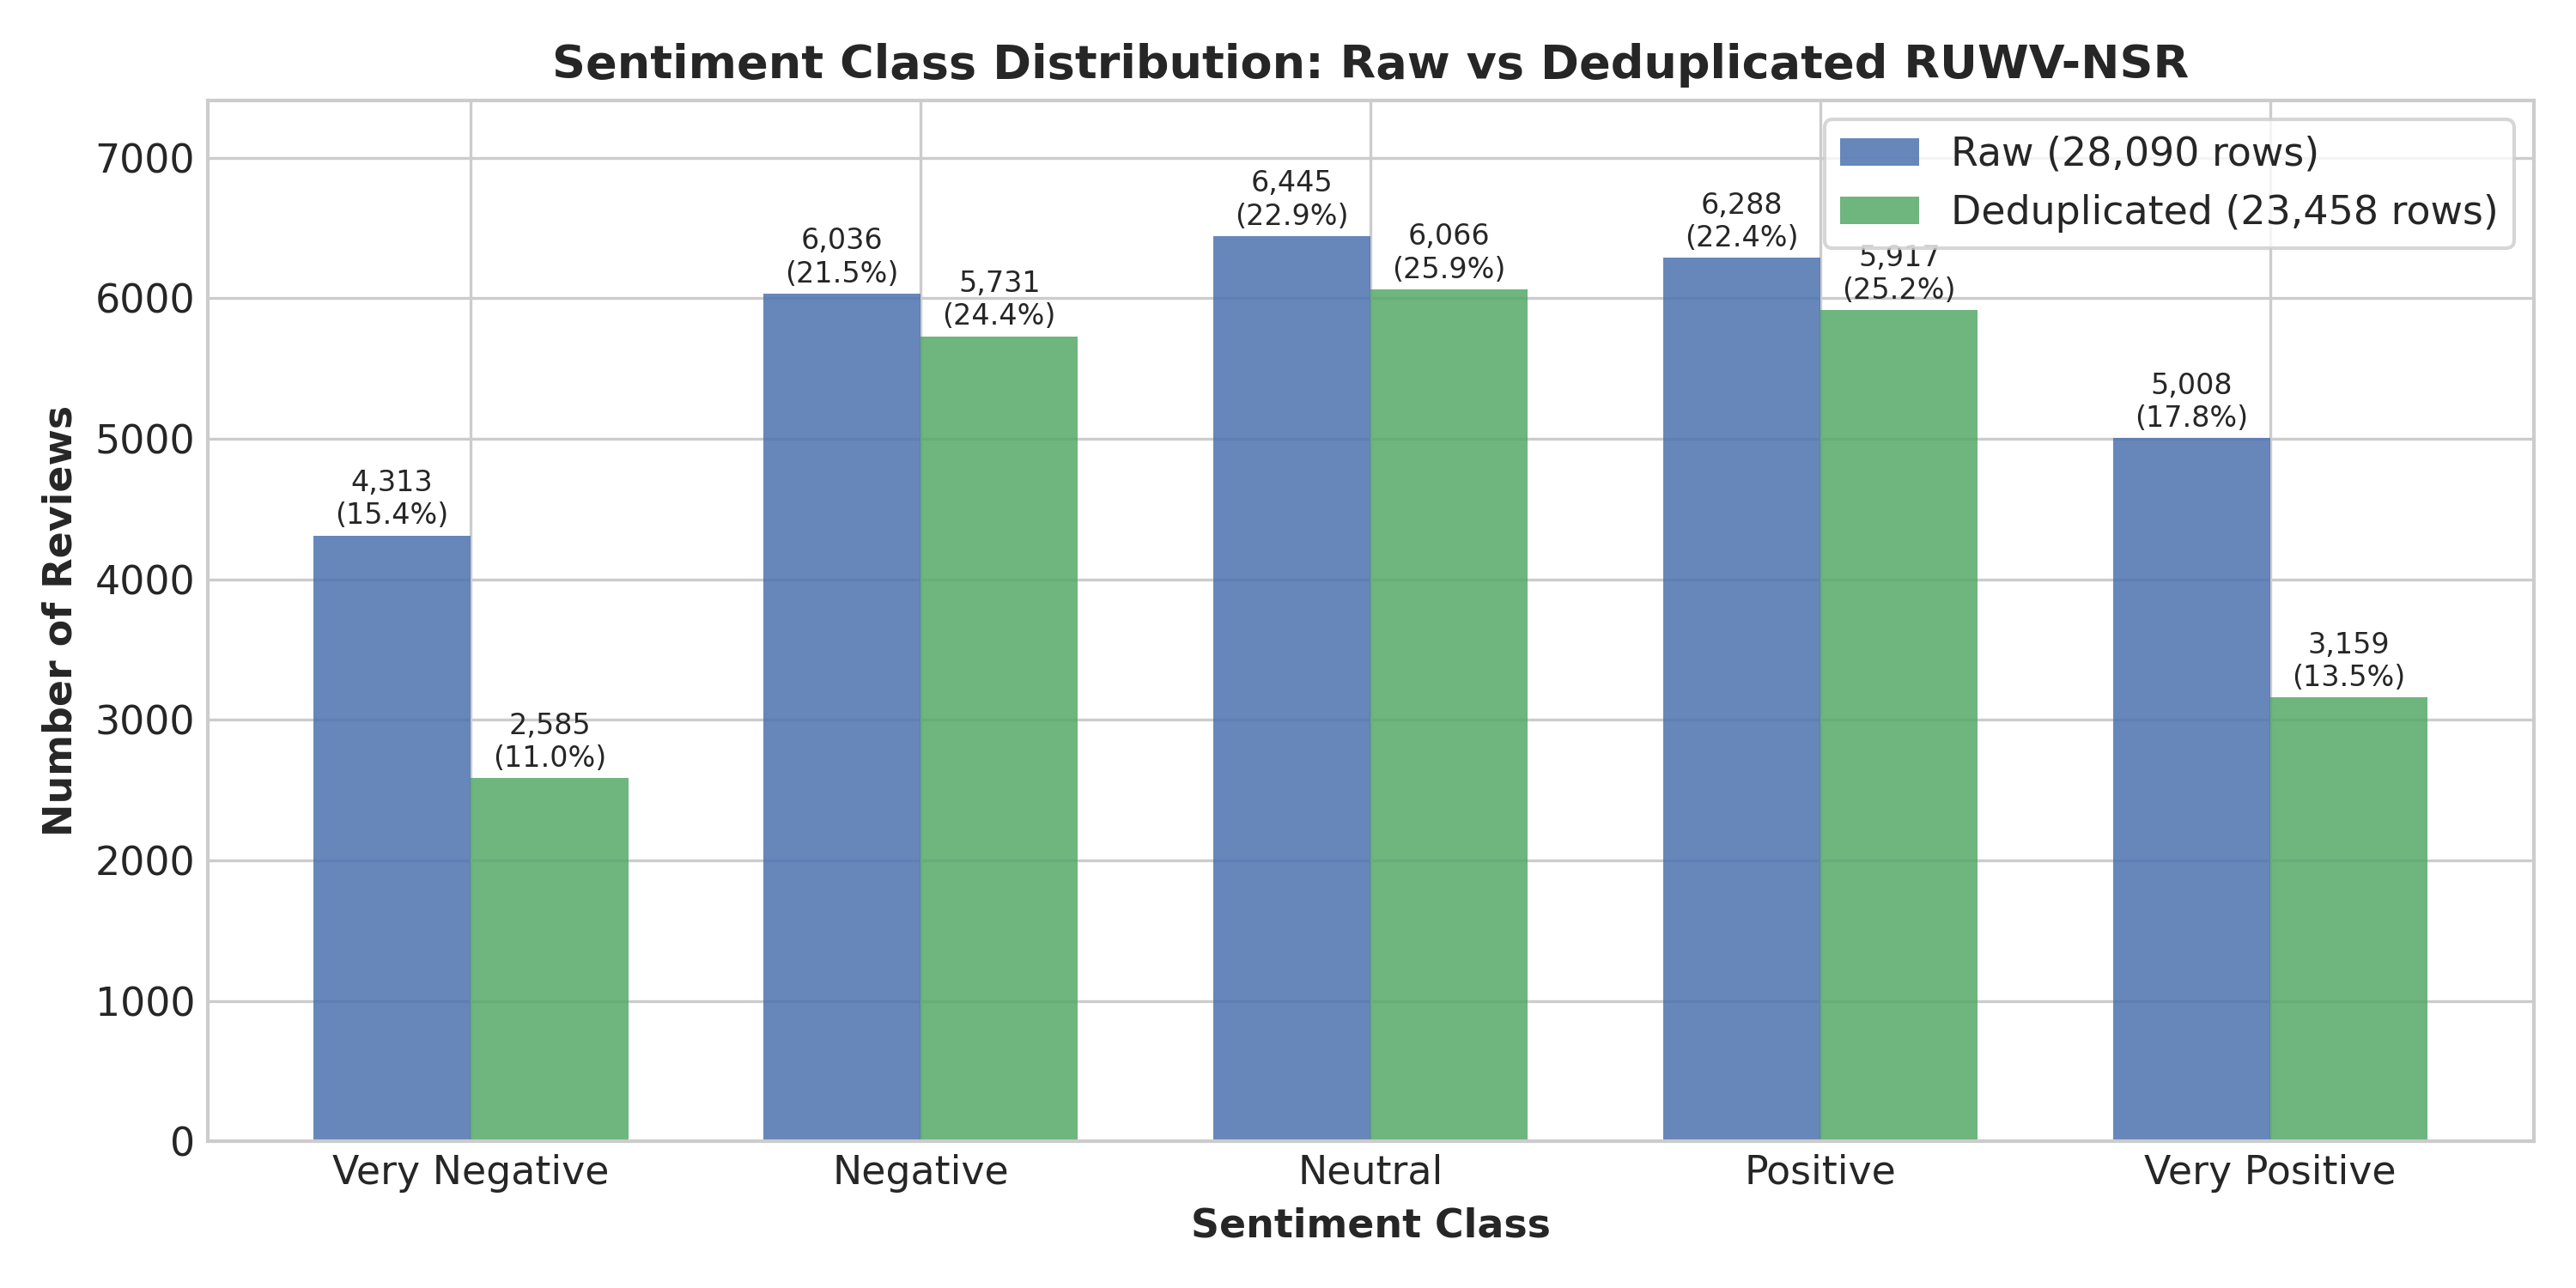

In [5]:
fig_path = os.path.join(PROJECT_ROOT, "results", "figures", "class_distribution.png")
if os.path.exists(fig_path):
    display(Image(filename=fig_path))
else:
    print("Distribution plot not found at:", fig_path)
